# 03 - Looking at specific regions of the genome

So far every measurement used the whole genome at once. But a genome is not uniform: it
is made of genes that do different jobs and are under different pressure. The paper did
the same thing, measuring each influenza segment separately.

RSV has **10 genes**, in this order along the genome:

`NS1 - NS2 - N - P - M - SH - G - F - M2 - L`

Two are worth knowing by name:

- **G** (attachment glycoprotein) - sits on the virus surface, the most variable gene,
  under constant pressure from antibodies.
- **F** (fusion protein) - also on the surface, and the target of the new preventives
  (nirsevimab, the RSVpreF vaccine).

`scripts/build_gene_features.py` cuts every genome into these 10 genes by aligning it to
a reference genome with MAFFT, then measures composition in each one separately.

In [1]:
import sys, os, subprocess
sys.path.insert(0, os.path.abspath("../src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = os.path.abspath("..")          # repo root; R scripts expect to run from here
pd.set_option("display.width", 120)

def run_r(script):
    """Run one of the R figure scripts from the repo root and report what it wrote."""
    r = subprocess.run(["Rscript", script], capture_output=True, text=True, cwd=ROOT)
    print(r.stdout.strip() or r.stderr.strip()[-400:])

def show(fig):
    """Display a figure from results/figures/ inline."""
    display(Image(os.path.join(ROOT, "results", "figures", fig)))


In [2]:
g = pd.read_csv("../data/processed/rsv_gene_features.tsv", sep="\t")
GENES = ["NS1","NS2","N","P","M","SH","G","F","M2","L"]
print(len(g), "rows =", g["Accession ID"].nunique(), "genomes x", g.gene.nunique(), "genes")
g.drop(columns=["Accession ID"]).head(3)

330380 rows = 33038 genomes x 10 genes


,gc_content,valid_len,freq_CG,freq_GC,freq_GG,freq_CC,oe_CG,oe_GC,oe_GG,oe_CC,Subtype,gene,Lineage,year,region
0,0.302381,420,0.0,0.033413,0.02864,0.023866,0.0,1.463992,1.159786,1.131423,A,NS1,A.D.4.1,2022,Africa
1,0.307143,420,0.0,0.033413,0.02864,0.026253,0.0,1.418881,1.125424,1.204741,A,NS1,A.D.3,2022,Africa
2,0.307143,420,0.0,0.033413,0.02864,0.026253,0.0,1.418881,1.125424,1.204741,A,NS1,A.D.3,2022,Africa


## Composition gene by gene

This is the main table of this notebook. `freq_CG`, `freq_GC` and `freq_GG` are the raw
frequencies of those dinucleotides inside each gene.

In [3]:
tab = (g.groupby(["Subtype","gene"])
        .agg(n=("gc_content","size"), length=("valid_len","median"),
             gc=("gc_content","mean"),
             freq_CG=("freq_CG","mean"), freq_GC=("freq_GC","mean"), freq_GG=("freq_GG","mean"),
             oe_CG=("oe_CG","mean"), oe_GG=("oe_GG","mean"))
        .reset_index())
tab["gene"] = pd.Categorical(tab["gene"], GENES, ordered=True)
tab = tab.sort_values(["Subtype","gene"])
tab.round(4)

,Subtype,gene,n,length,gc,freq_CG,freq_GC,freq_GG,oe_CG,oe_GG
6,A,NS1,15458,420.0,0.3047,0.0004,0.0330,0.0275,0.0161,1.0860
7,A,NS2,15458,375.0,0.3422,0.0020,0.0284,0.0242,0.0715,1.2784
5,A,N,15458,1176.0,0.3696,0.0058,0.0420,0.0505,0.1753,1.0956
8,A,P,15458,726.0,0.3570,0.0050,0.0262,0.0276,0.1561,0.7883
3,A,M,15458,771.0,0.3661,0.0066,0.0387,0.0192,0.2034,0.8535
9,A,SH,15458,195.0,0.3188,0.0090,0.0297,0.0108,0.4039,1.0035
1,A,G,15458,969.0,0.4300,0.0115,0.0336,0.0199,0.3264,1.6279
0,A,F,15458,1725.0,0.3525,0.0068,0.0356,0.0292,0.2188,0.9450
4,A,M2,15458,585.0,0.3637,0.0134,0.0344,0.0257,0.4061,0.7686
2,A,L,15458,6498.0,0.3080,0.0063,0.0219,0.0272,0.2680,1.0710


### Patterns to notice

1. **The G gene stands out.** It has the highest GC content of any gene (0.43 in RSV-A vs
   about 0.33 genome-wide) and the highest GpG O/E. It is the most variable gene, so this
   is a region worth focusing on.
2. **CpG suppression is not uniform along the genome.** Some genes are far more suppressed
   than others.
3. **NS1 and NS2 in RSV-A have almost no CpG at all** - look at how small `freq_CG` is for
   those two rows compared with RSV-B. We look at this directly below.

In [4]:
run_r("R/figures_genes.R")

fig11 written


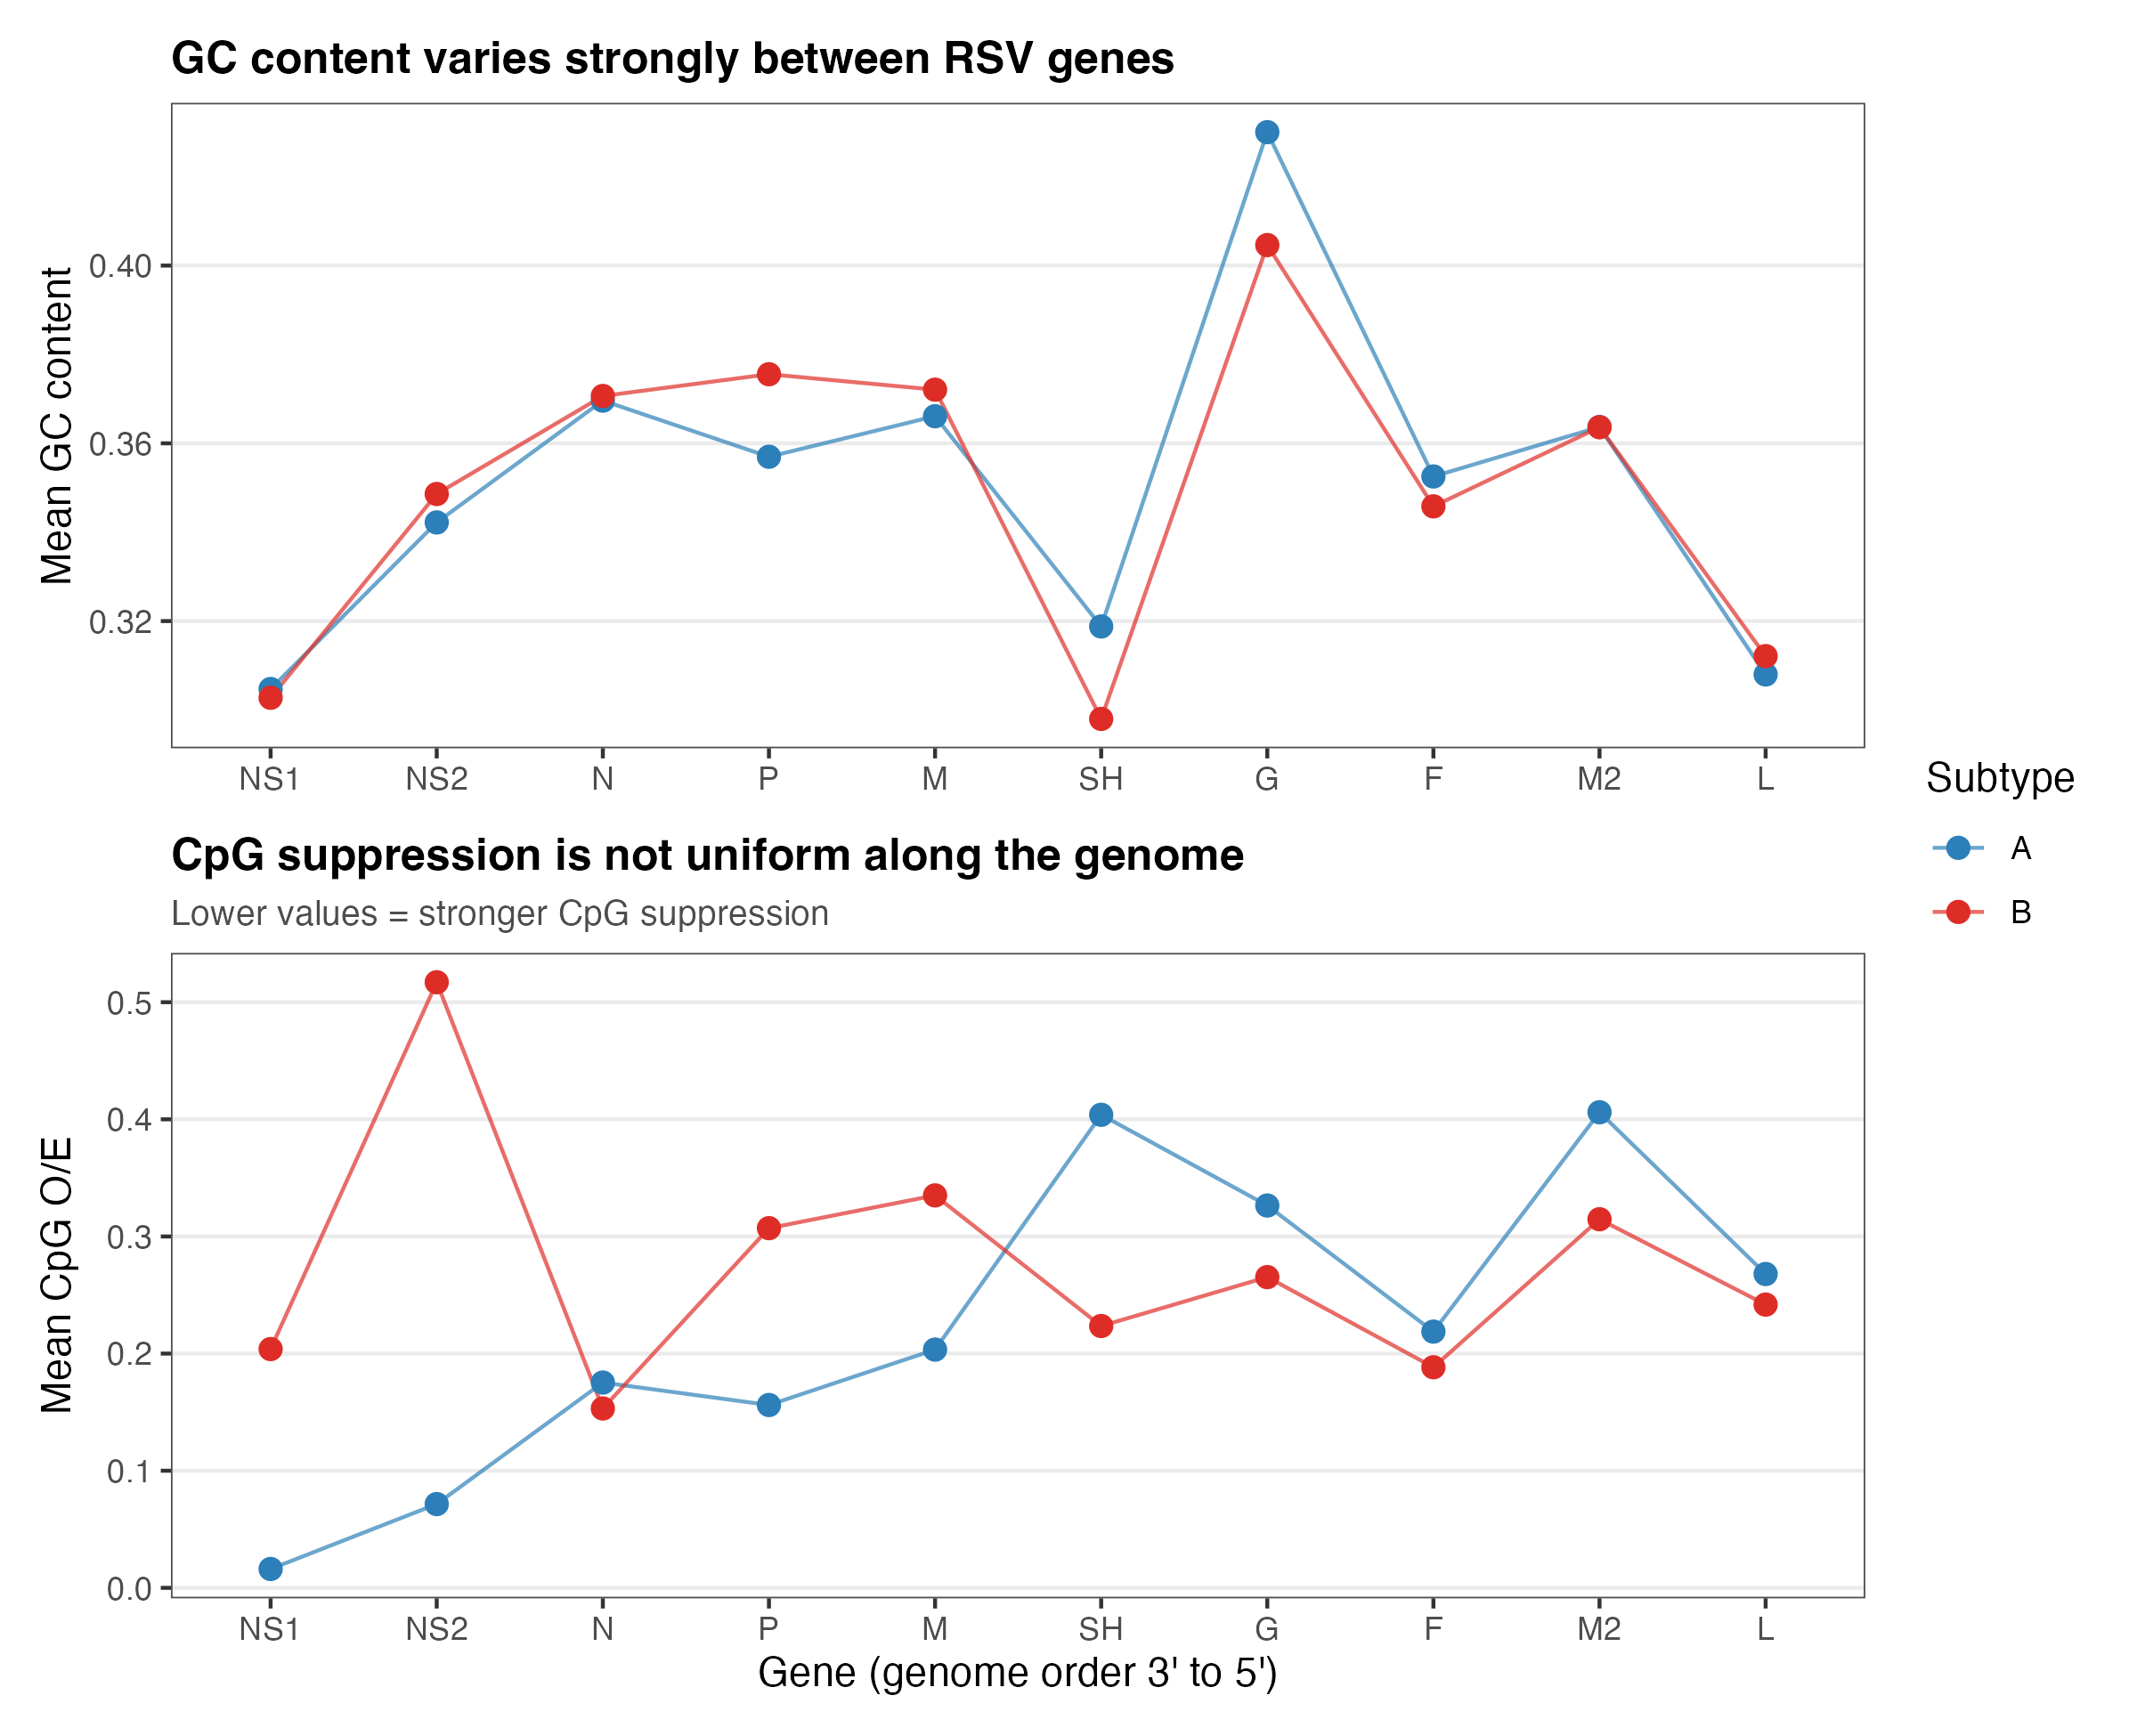

In [5]:
show("fig9_gene_composition.png")

## Zooming in: the G gene

Since G is the most distinctive region, here is its composition on its own, over time and
by subtype. This is the kind of focused, single-region view that is easy to interpret.

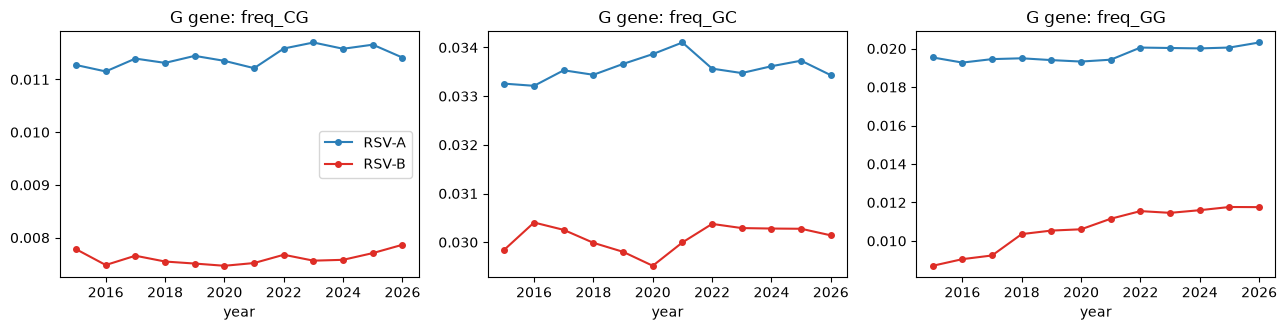

In [6]:
G = g[g.gene == "G"]
yr = (G[(G.year >= 2015) & (G.year <= 2026)]
      .groupby(["Subtype","year"])
      .agg(n=("gc_content","size"), gc=("gc_content","mean"),
           freq_CG=("freq_CG","mean"), freq_GC=("freq_GC","mean"), freq_GG=("freq_GG","mean"))
      .reset_index())
yr = yr[yr.n >= 20]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4), sharex=True)
for i, col in enumerate(["freq_CG","freq_GC","freq_GG"]):
    for s, c in zip("AB", ["#2c7fb8","#de2d26"]):
        x = yr[yr.Subtype == s]
        ax[i].plot(x.year, x[col], "-o", color=c, ms=4, label=f"RSV-{s}")
    ax[i].set_title(f"G gene: {col}"); ax[i].set_xlabel("year")
ax[0].legend(); plt.tight_layout(); plt.show()

## The clearest pattern in the whole project

NS1 and NS2 are RSV's **interferon antagonist** genes - their job is to switch off the
cell's antiviral alarm. In RSV-A these two genes have had almost all their CpG removed.

In [7]:
cmp = (g[g.gene.isin(["NS1","NS2","N","L"])]
       .groupby(["gene","Subtype"])
       .apply(lambda s: pd.Series({
           "CpG per gene": (s.freq_CG * s.valid_len).mean(),
           "% genomes with zero CpG": (s.freq_CG == 0).mean() * 100,
           "GC content": s.gc_content.mean()}), include_groups=False)
       .round(3))
cmp

CpG per gene  % genomes with zero CpG  GC content
gene Subtype                                                   
L    A              41.211                    0.000       0.308
     B              38.235                    0.000       0.312
N    A               6.862                    0.000       0.370
     B               6.088                    0.000       0.371
NS1  A               0.159                   84.778       0.305
     B               1.943                    0.506       0.303
NS2  A               0.758                   34.189       0.342
     B               5.641                    0.000       0.349

**Read the NS1 rows.** RSV-A averages about 0.16 CpG in the whole gene and roughly 85% of
RSV-A genomes contain **none at all**, while RSV-B has around 1.9 and almost always has
some. GC content is nearly identical between them (0.305 vs 0.303), so this is not a side
effect of base composition - it is specific to CpG. N and L, shown for comparison, behave
the same in both subtypes.

This is an observation, not a proven mechanism. It is consistent with ZAP pressure, but
showing that would need laboratory work.

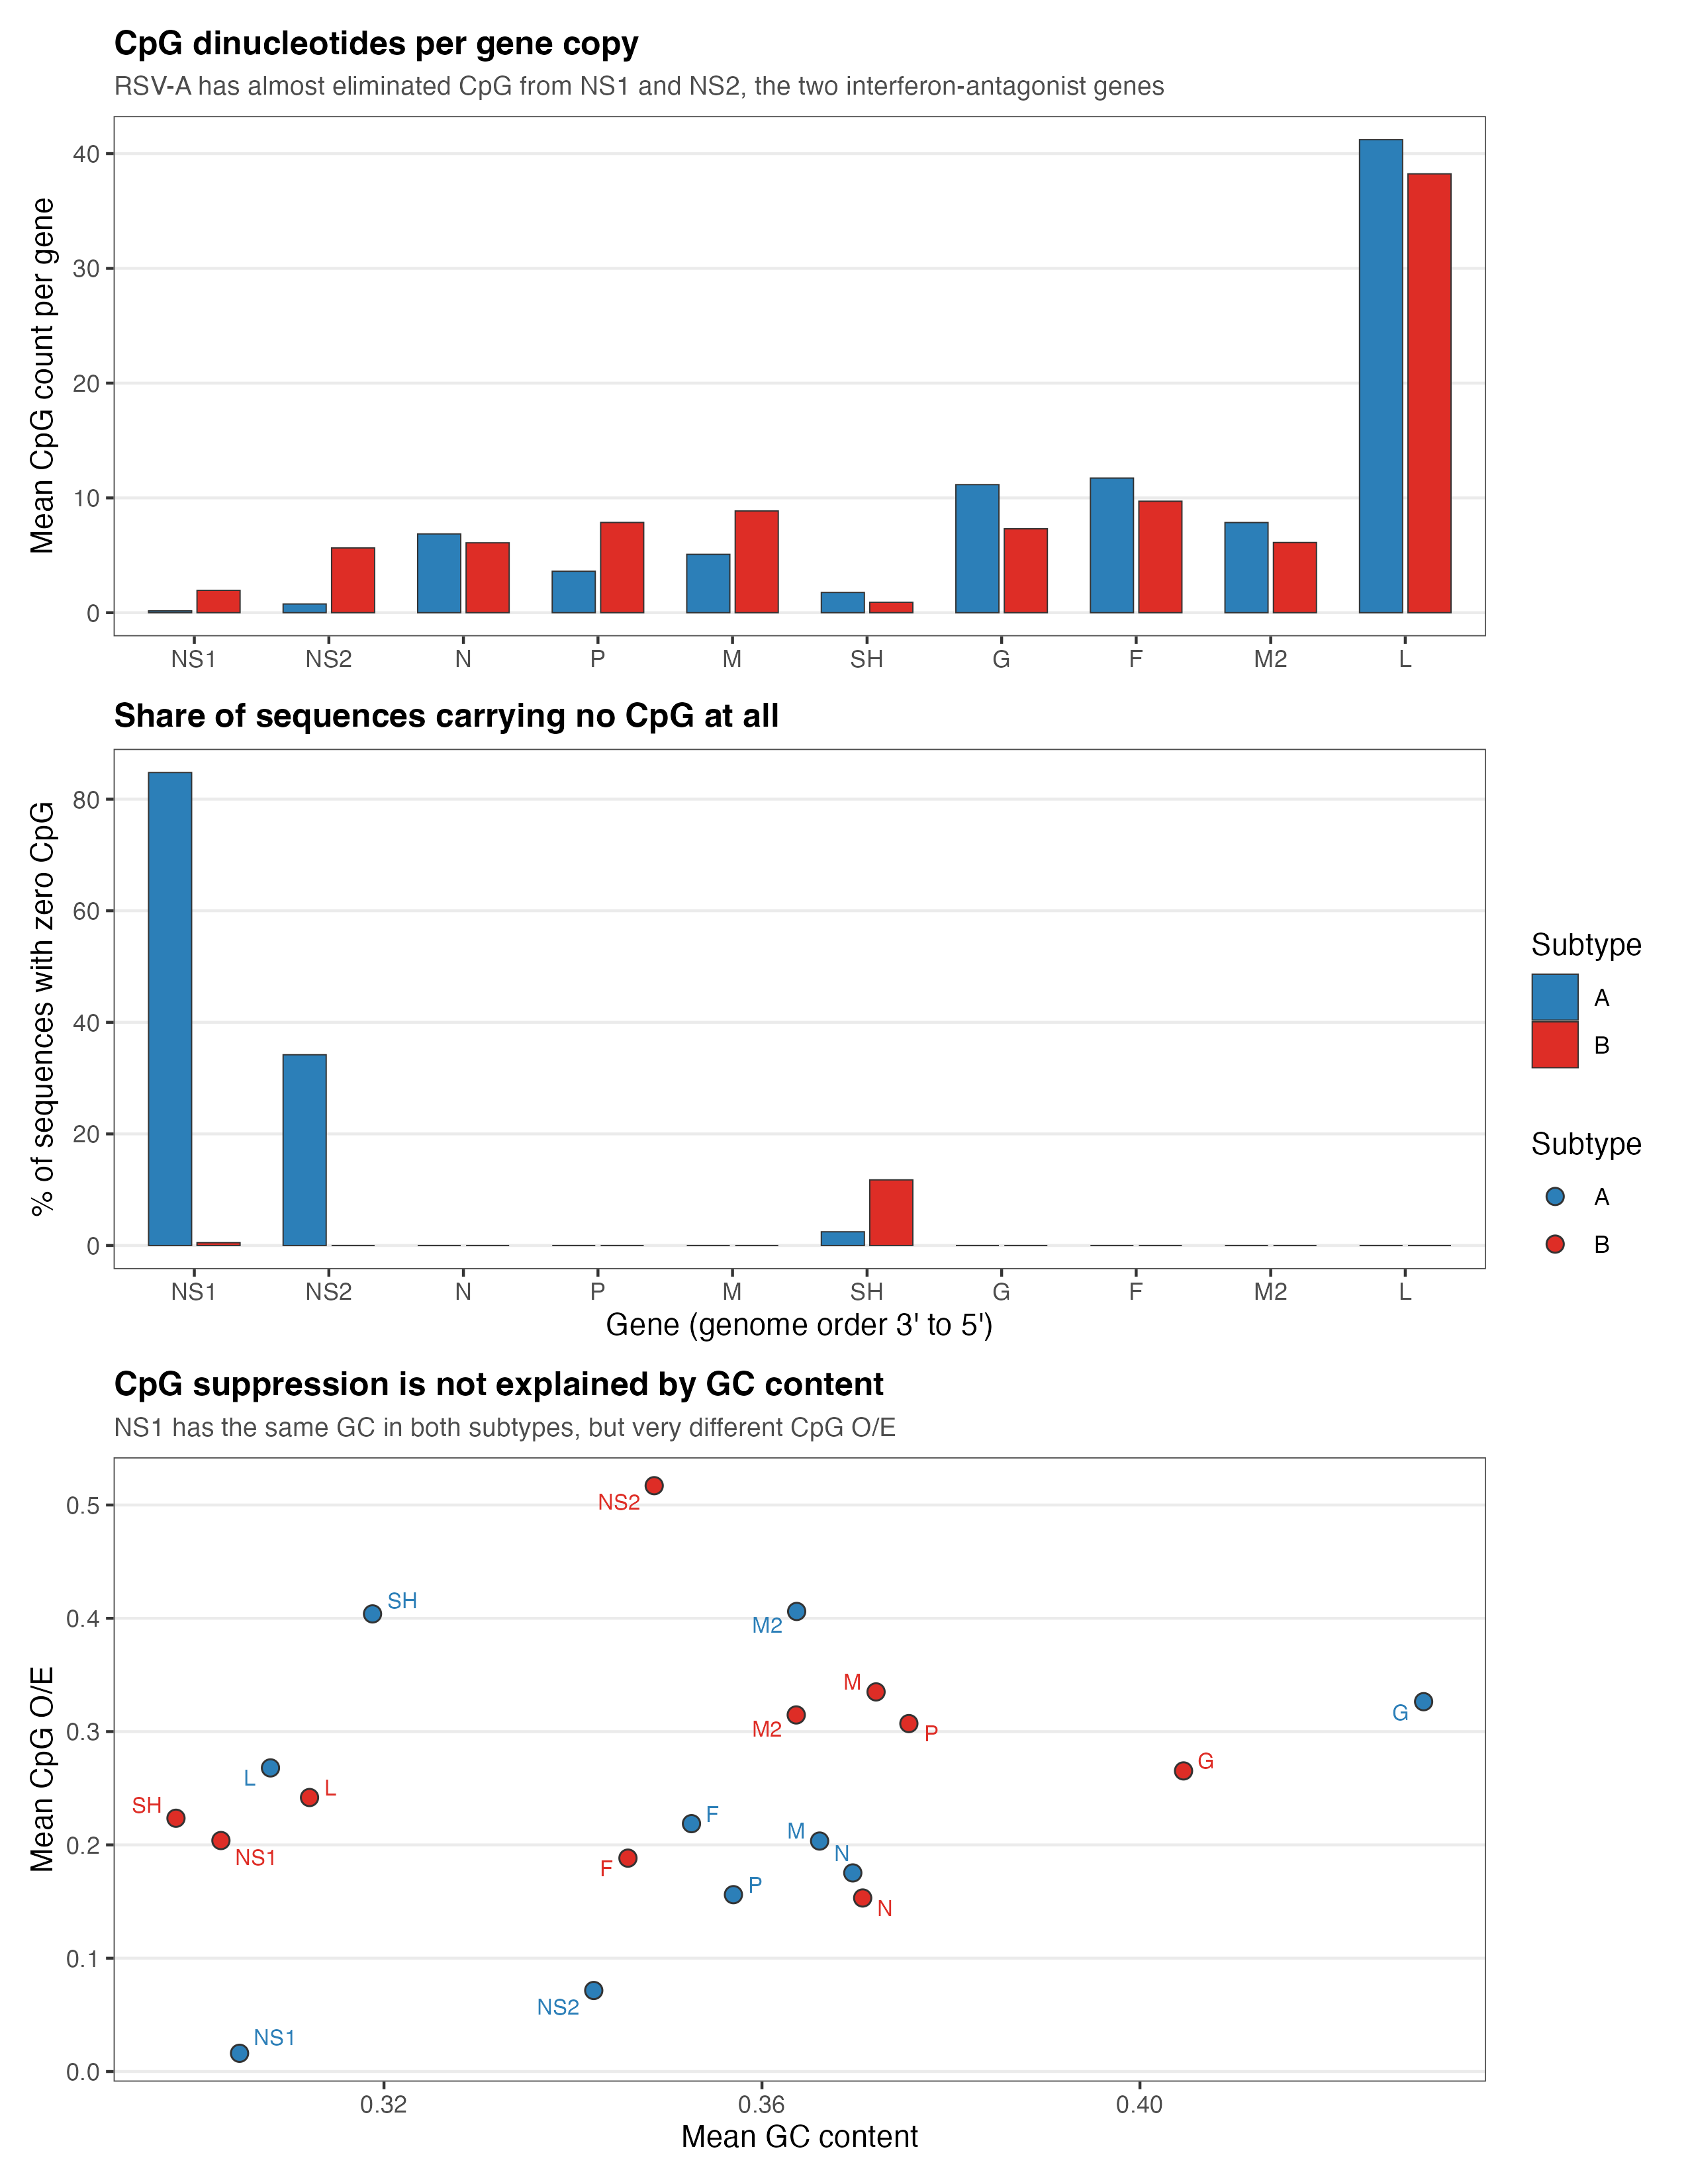

In [8]:
show("fig11_cpg_depletion.png")